# Customer Segmentation Using K-means


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

Matplotlib is building the font cache; this may take a moment.


## Task 1: Load and inspect

In [4]:
df = pd.read_csv('Mall_Customers.csv')
print('Rows, columns:', df.shape)
print(df.head())
df.info()
print('\nMissing values per column:')
print(df.isna().sum())
print(df.describe())

Rows, columns: (200, 5)
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB

Missing values per column:
CustomerID                

In [5]:

income = 'Annual Income (k$)'
spend = 'Spending Score (1-100)'
X = df[[income, spend]]

## Task 2: Visualize the raw features

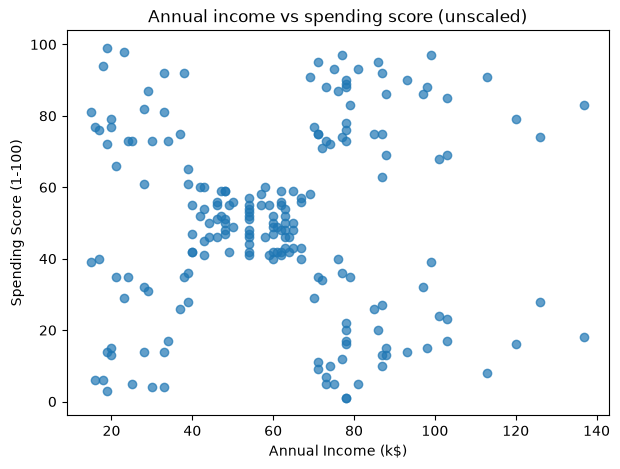

In [6]:
plt.figure(figsize=(7,5))
plt.scatter(X[income], X[spend], alpha=0.7)
plt.xlabel(income); plt.ylabel(spend)
plt.title('Annual income vs spending score (unscaled)')
plt.show()

## Task 3: Standardize

In [7]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(pd.DataFrame(X_scaled, columns=[income, spend]).describe().loc[['mean','std']].round(3))

      Annual Income (k$)  Spending Score (1-100)
mean              -0.000                  -0.000
std                1.003                   1.003


## Task 4: Elbow method (WCSS) + silhouette as supporting evidence

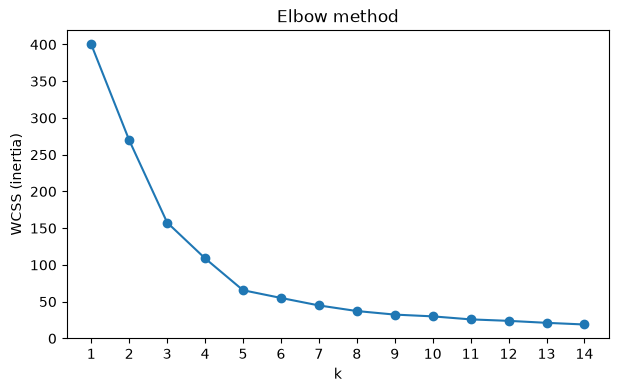

k=2: silhouette = 0.321
k=3: silhouette = 0.467
k=4: silhouette = 0.494
k=5: silhouette = 0.555
k=6: silhouette = 0.540
k=7: silhouette = 0.528
k=8: silhouette = 0.455
k=9: silhouette = 0.457
k=10: silhouette = 0.443


In [22]:
wcss, sil = [], []
ks = range(1, 15)
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    wcss.append(km.inertia_)
    if k > 1:
        sil.append(silhouette_score(X_scaled, km.labels_))

plt.figure(figsize=(7,4))
plt.plot(list(ks), wcss, marker='o')
plt.xlabel('k'); plt.ylabel('WCSS (inertia)'); plt.title('Elbow method')
plt.xticks(list(ks)); plt.show()

for k, s in zip(range(2, 11), sil):
    print(f'k={k}: silhouette = {s:.3f}')

## Task 5: Fit K-means and plot clusters + centroids

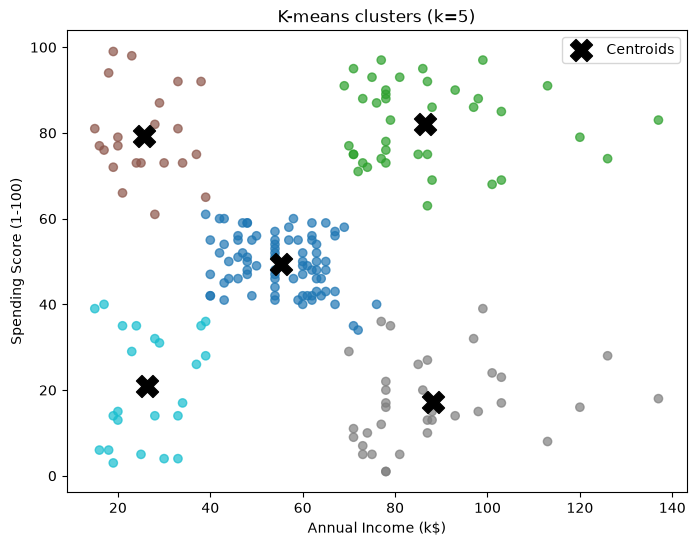

In [ ]:
k = 5  
kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
df['Cluster'] = kmeans.fit_predict(X_scaled)

# Converting centroids back to original units so they line up with the plot
centroids = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(8,6))
plt.scatter(df[income], df[spend], c=df['Cluster'], cmap='tab10', alpha=0.7)
plt.scatter(centroids[:,0], centroids[:,1], c='black', marker='X', s=250, label='Centroids')
plt.xlabel(income); plt.ylabel(spend)
plt.title(f'K-means clusters (k={k})'); plt.legend(); plt.show()

## Task 6: Summarize clusters

In [25]:
summary = df.groupby('Cluster').agg(
    Customer_Count=('Cluster', 'size'),
    Average_Income=(income, 'mean'),
    Average_Spending=(spend, 'mean'),
    Average_Age=('Age', 'mean')   
).round(1)
print(summary)

         Customer_Count  Average_Income  Average_Spending  Average_Age
Cluster                                                               
0                    81            55.3              49.5         42.7
1                    39            86.5              82.1         32.7
2                    22            25.7              79.4         25.3
3                    35            88.2              17.1         41.1
4                    23            26.3              20.9         45.2


## Optional: compare with other k values

In [26]:
for k_try in [5, 6, 7]:
    km = KMeans(n_clusters=k_try, n_init=10, random_state=42).fit(X_scaled)
    print(f'k={k_try}: WCSS={km.inertia_:.1f}, silhouette={silhouette_score(X_scaled, km.labels_):.3f}')

k=5: WCSS=65.6, silhouette=0.555
k=6: WCSS=55.1, silhouette=0.540
k=7: WCSS=44.9, silhouette=0.528
